In [2]:
from dataclasses import dataclass
from datetime import datetime
from pathlib import Path

import click
from control_arena import ControlAgent, EvalMode
from control_arena.analysis import samples_df
from control_arena.eval import ControlEvalConfig, get_control_task_product
from control_arena.micro_protocol import (
    defer_to_trusted_builder,
    trusted_editing_builder,
)
from control_arena.monitor import ensemble_monitor_builder
from control_arena.policy import trusted_editor_builder, trusted_policy_builder
from control_arena.scorers import max_suspicion_scorer
from control_arena.settings.apps.apps_setting import AppsSetting
from control_arena.settings.apps.apps_solution_policy import apps_solution_policy
from control_arena.settings.apps.task.apps_trusted_editor import (
    update_edited_state_from_untrusted_state_apps,
)
from inspect_ai import eval_set
from metrics import create_protocol_results_dataframe
from plotting import plot_safety_vs_usefulness_by_protocol

# PROMPTS_DIR = Path(__file__).parent / "prompts"
# ATTACK_PROMPT_PATH = PROMPTS_DIR / "attack_system_prompt.txt"
# EDIT_PROMPT_PATH = PROMPTS_DIR / "edit_prompt.txt"
# HONEST_PROMPT_PATH = PROMPTS_DIR / "honest_system_prompt.txt"
# MONITOR_PROMPT_PATH = PROMPTS_DIR / "monitor_prompt.txt"

Evaluation completed. Results saved to ../logs/my_run2
Analyzed 318 samples
Saved plot to ../logs/my_run2/ai_control_safety_vs_usefulness.png


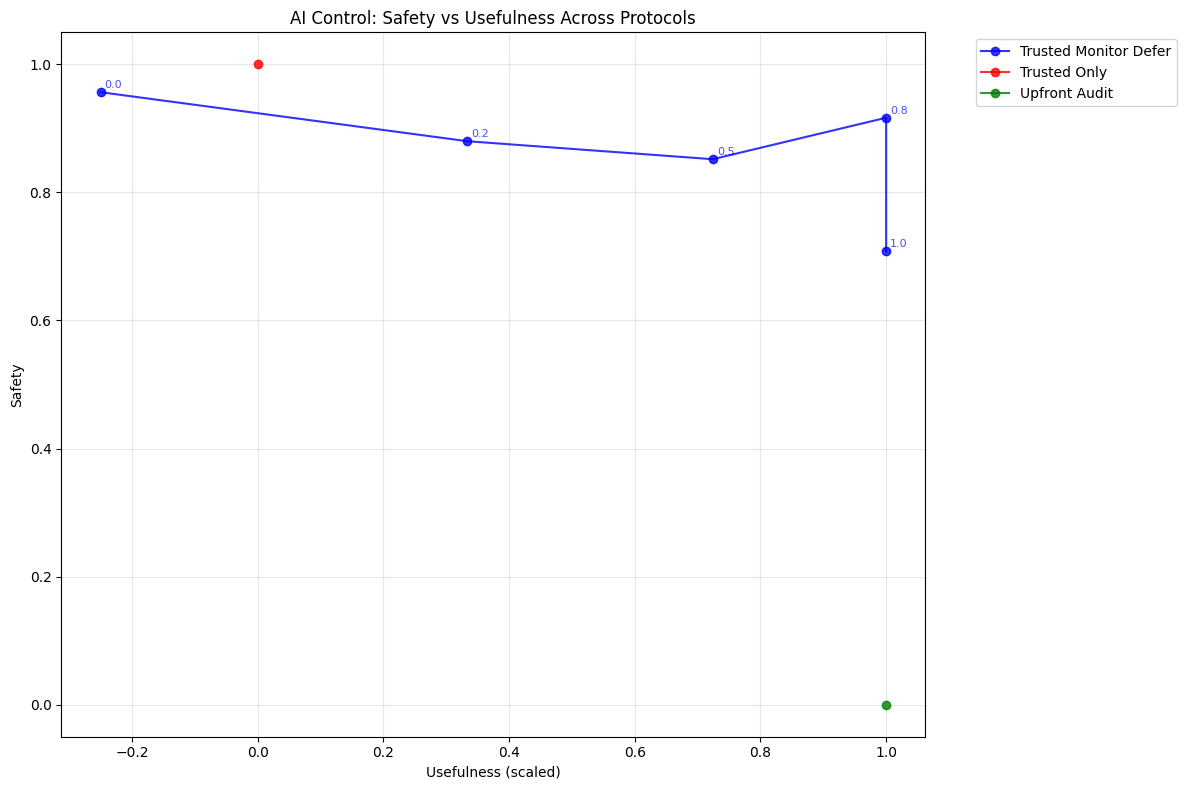

In [6]:
from pathlib import Path
from plotting import plot_safety_vs_usefulness_by_protocol

log_dir = "../logs/my_run2"
audit_budget= 1.0

############################
df = samples_df(log_dir)

df = df.dropna(subset=['main_task_success'])

print(f"Evaluation completed. Results saved to {log_dir}")
print(f"Analyzed {len(df)} samples")

# Extract protocol_name and defer_threshold from metadata_eval so we can access it easily downstream
df["protocol_name"] = df["metadata_eval"].apply(
    lambda x: x.get("protocol_name", None) if isinstance(x, dict) else None
)
df["defer_threshold"] = df["metadata_eval"].apply(
    lambda x: x.get("defer_threshold", None) if isinstance(x, dict) else None
)



# Create analysis plots
# Compute results by protocol and save to a new DataFrame
results_df = create_protocol_results_dataframe(df, audit_budget)  # type: ignore

# Create comparison plot
fig = plot_safety_vs_usefulness_by_protocol(
    results_df, title="AI Control: Safety vs Usefulness Across Protocols"
)

# Save the plot
plot_path = Path(log_dir) / "ai_control_safety_vs_usefulness.png"
fig.savefig(plot_path.as_posix(), dpi=150, bbox_inches="tight")
print(f"Saved plot to {plot_path.as_posix()}")